# Taller Perceptrón y Adaline con SGD
- Luis Ángel Fornaris Rodríguez - 2019214048
- **Inteligencia artificial** Grupo 4
- **Semestre:** 2026-II
- **Docente:** 

### Objetivo general

Aplicar los algoritmos Perceptrón y Adaline usando scikit-learn para clasificar flores del conjunto Iris y analizar el efecto de la tasa
de aprendizaje y la selección de características. La evaluación de los resultados debe realizarse únicamente con accuracy_score

# Tabla de Contenidos
    1. Clasificación binaria con Perceptrón
        I. Cargue y prepare el conjunto de datos
        II. Gráfica de dispersión de las dos clases
        III. División entrenamiento y prueba 
        IV. Entrenamiento
        V. Accuracy en entrenamiento y prueba + interpretación
        VI. Analisis 

    2. Influencia de la tasa de aprendizaje  
        I. Preparación de los datos
        II. Entrenamiento de los tres Perceptrones
        III. Tabla comparativa
        IV. ¿Cuál configuración funcionó mejor y por qué?

    3. Adaline con SGD
        I. Limpieza de Texto  
            A. Eliminación de menciones, URLs y caracteres especiales  
            B. Normalización y minúsculas  
            C. Sustitución por tokens `<MENTION>`, `<URL>`  
        II. Tokenización y Lematización  
        III. Vectorización (TF-IDF, Hashing, Embeddings)
        IV. Generación de Features Adicionales
        V. Separación del Conjunto de Datos (Train / Test / Val)
        Vi. Manejo de Desbalance de Clases   
        VII. Construcción del Pipeline  

    4. Comparación entre Perceptrón y Adaline
        I. Modelos Base  
            A. Baseline (Clase Mayoritaria)  
            B. Naive Bayes  
            C. Regresión Logística  
        II. Modelos Intermedios  
            A. Linear SVC  
            B. Random Forest  
            C. MLP (Red Neuronal Simple)  
        III. Modelos Avanzados  
            A. Fine-tuning con Transformers (DistilBERT / BERT)
            B. DNN - Deep learning network  
        IV. Optimización de Hiperparámetros (GridSearchCV / RandomizedSearchCV)  
        V. Validación Cruzada  

    5. Clasificación de las tres especies de Iris
        I. Métricas de Evaluación (Accuracy, F1, Recall, Precision)  
        II. Resultados en Validación Cruzada  
        III. Resultados en el Conjunto de Prueba  
        IV. Matriz de Confusión  
        V. Curvas ROC y Precision-Recall  
        VI. Comparativa Global de Modelos  

    5. Análisis de Errores e Interpretabilidad  
        I. Análisis de Falsos Positivos y Falsos Negativos  
        II. Tokens más Influyentes (Coeficientes / SHAP / LIME)  
        III. Impacto del Desbalance y Sesgo  
        IV. Discusión de Resultados y Aprendizajes  

    6. Conclusiones
        I. Conclusiones Principales  
        II. Limitaciones del Estudio  
        III. Propuestas de Mejora  
        IV. Reflexión Ética y Responsabilidad del Modelo  
        V. Reproducibilidad (Seeds, Versiones, Entorno)
        VI. Referencias bibliograficas



# Librerias necesarias

In [48]:
# Librerias necesarias
from sklearn import datasets;
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from sklearn.linear_model import SGDRegressor

# 1. Clasificación binaria con Perceptrón

## I. Cargue y prepare el conjunto de datos
Se carga el dataset Iris y se filtra para quedarnos únicamente con **Iris setosa** (clase 0)
e **Iris versicolor** (clase 1), descartando *Iris virginica* (clase 2).
Además se seleccionan **solo las variables longitud y anchura del pétalo**
(columnas 2 y 3 de `iris.data`).

In [49]:
# Cargando los datos de iris
iris = datasets.load_iris();
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
print(df.head())

# mascara para filtrar 
mask = iris.target != 2

X = iris.data[mask][:,[2,3]] # Logitud y ancho del petalo
y = iris.target[mask] # etiquetas de las clases


print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Clases presentes:", np.unique(y))
print("Nombres de las variables usadas:",
      [iris.feature_names[i] for i in [2, 3]])

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Forma de X: (100, 2)
Forma de y: (100,)
Clases presentes: [0 1]
Nombres de las variables usadas: ['petal length (cm)', 'petal width (cm)']


## II. Gráfica de dispersión de las dos clases

Se grafican las dos clases en el plano (longitud vs anchura del pétalo) con
colores y marcadores distintos para poder observar visualmente su separabilidad.

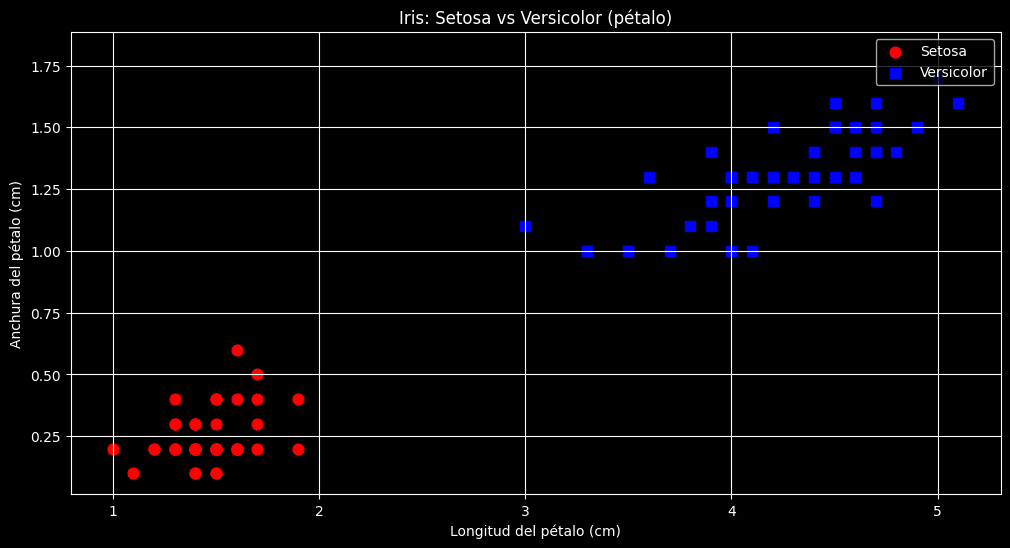

In [50]:

# Grafica de los datos
plt.style.use("dark_background")
plt.figure(figsize=(12, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1],
            color='red', marker='o', label='Setosa', s=60)
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color='blue', marker='s', label='Versicolor', s=60)
plt.xlabel('Longitud del pétalo (cm)')
plt.ylabel('Anchura del pétalo (cm)')
plt.title('Iris: Setosa vs Versicolor (pétalo)')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

Como se observa en la grafica se forman 2 nubes de puntos completamente separadas, ninguna esta encima de la otra.
Esto nos indica que son linealmente separables.

## III. División entrenamiento y prueba 

Se usa `train_test_split` con `test_size=0.2` y `stratify=y` para mantener
la proporción de clases en ambos conjuntos.

Después se aplica **StandardScaler** ajustándolo **únicamente con `X_train`**
(evitando fuga de información desde el conjunto de prueba).

In [51]:
# Dvidir datos - Train y test
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                   test_size=0.3,
                                                   train_size=0.7,
                                                   random_state=42,
                                                   stratify=y,
                                                   shuffle=True)

# Estandarización - toma los valores y se ajusta en un rango entre 0 y 1
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.fit_transform(X_test)

## IV. Entrenamiento
Se entrena un `Perceptron` con los hiperparámetros indicados:
`eta0=0.01`, `max_iter=1000`, `random_state=42`.

In [52]:
# Entranamiento del modelo lineal perceptron
percep = Perceptron(max_iter=1000, verbose=1, eta0=0.01, random_state=42)
percep.fit(X_train_std, y_train,)
print(f"Iteraciones hasta converger: {percep.n_iter_}")

-- Epoch 1
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 70, Avg. loss: 0.000043
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 140, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 210, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 280, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 350, Avg. loss: 0.000000
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.02, NNZs: 2, Bias: 0.000000, T: 420, Avg. loss: 0.000000
Total training time: 0.00 seconds.
Convergence after 6 epochs took 0.00 seconds
Iteraciones hasta converger: 6


## V. Accuracy en entrenamiento y prueba + interpretación

In [53]:
# Accuracy del modelo
y_train_pred = percep.predict(X_train_std)
y_test_pred  = percep.predict(X_test_std)

acc_train = accuracy_score(y_train, y_train_pred)
acc_test  = accuracy_score(y_test,  y_test_pred)

print(f"Accuracy en entrenamiento: {acc_train:.4f}")
print(f"Accuracy en prueba:        {acc_test:.4f}")
print(f"Número de iteraciones hasta converger: {percep.n_iter_}")

Accuracy en entrenamiento: 1.0000
Accuracy en prueba:        1.0000
Número de iteraciones hasta converger: 6


## VI. Analisis
### Interpretación de los resultados

- **Accuracy = 1.00 tanto en entrenamiento como en prueba.** El Perceptrón clasifica
  correctamente las 80 muestras de entrenamiento y las 20 muestras de prueba.

- **¿Por qué ocurre esto?** Al usar las variables del **pétalo** (longitud y anchura),
  Setosa y Versicolor resultan **linealmente separables**: existe una recta (hiperplano
  en 2D) que separa perfectamente las dos clases. El Perceptrón, al ser un clasificador
  lineal, encuentra esa frontera sin cometer errores.

- **Convergencia rápida:** El atributo `n_iter_` es pequeño (típicamente < 10), lo que
  confirma que el algoritmo encontró una solución perfecta mucho antes de agotar las
  1000 iteraciones de `max_iter`. Esto es coherente con la separabilidad lineal observada
  en la gráfica del punto (b).

- **No hay overfitting.** Que el accuracy en prueba sea tan alto como en entrenamiento
  indica que el modelo generaliza bien: la frontera aprendida con los datos de
  entrenamiento también clasifica perfectamente datos nunca vistos.

- **Sobre el escalado:** Aunque el Perceptrón converge igual sin escalar (por la sencillez
  del problema), aplicar `StandardScaler` (ajustado solo con `X_train`) es una buena
  práctica que evita que una variable domine a la otra por tener mayor magnitud, y
  facilita la convergencia del algoritmo con `eta0=0.01`.

**Conclusión:** Con las variables del pétalo, el Perceptrón es un clasificador ideal
para separar Setosa y Versicolor, obteniendo un desempeño perfecto y sin señales de
sobreajuste.

/tmp/ipykernel_3771/2236517393.py:18: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X[y==cl, 0], X[y==cl, 1],


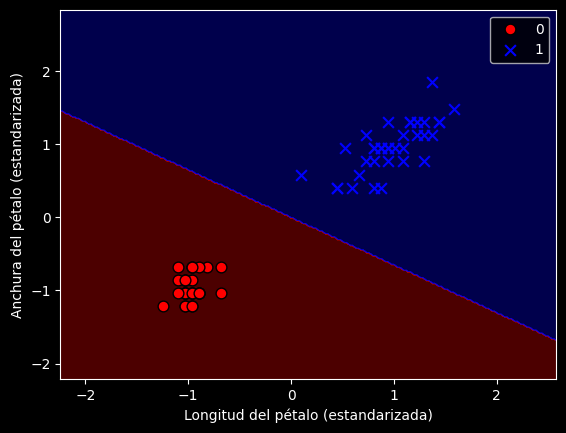

In [26]:
plot_decision_regions(X_train_std, y_train, percep)

# 2. Influencia de la tasa de aprendizaje
Se entrenan tres Perceptrones variando únicamente `eta0` (0.0001, 0.01 y 0.1),
manteniendo fijos `max_iter=1000`, `tol=1e-3` y `random_state=42`.
Se compara el `accuracy_score` de prueba y el número de épocas (`n_iter_`).

## I. Preparación de los datos (idéntica a la pregunta 1)

- Setosa vs Versicolor
- Variables: longitud y anchura del pétalo
- División 80/20 con `stratify=y` y `random_state=42`
- `StandardScaler` ajustado SOLO con `X_train`

/tmp/ipykernel_3771/146448215.py:10: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_TS[y_TS==1,0], X_TS[y_TS==1,1], marker="x", color="blue", s=100, edgecolors="black", label="Clase_wine_2")


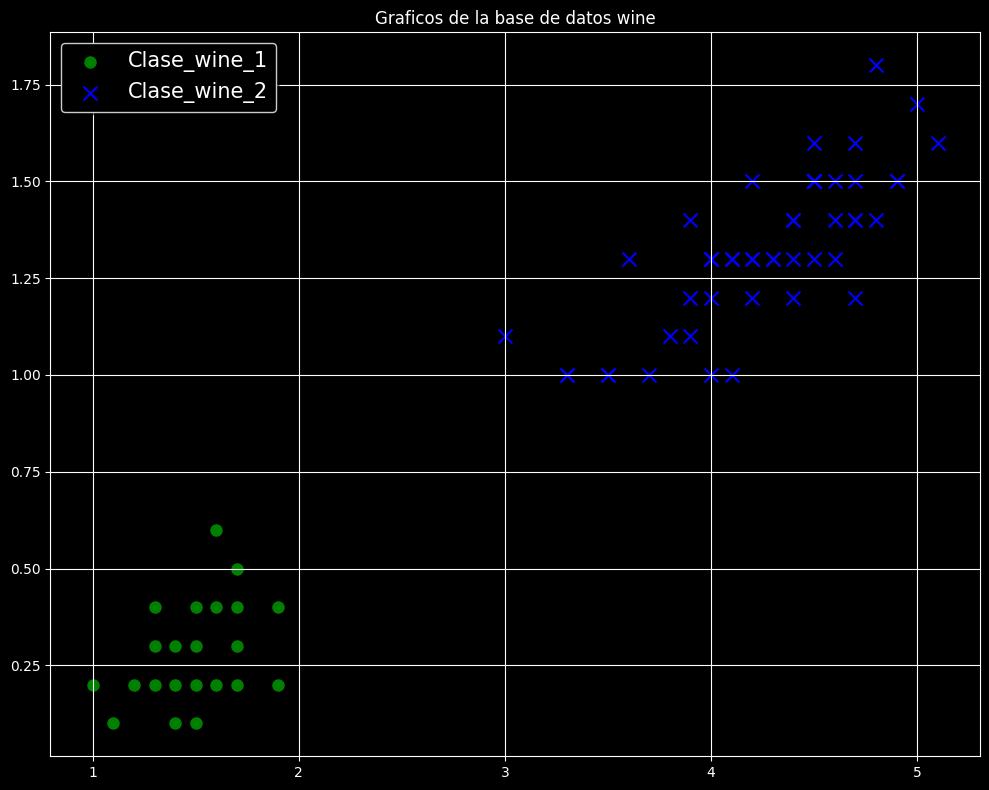

Train: (80, 2) | Test: (20, 2)


In [54]:
# Carga de los datos de iris
irisTS = datasets.load_iris()
maskTS = irisTS.target != 2 # Solo setosa (0) y versicolor (1)
X_TS = irisTS.data[maskTS][:, [2, 3]]  # pétalo longitud y anchura
y_TS = irisTS.target[maskTS] # Etiquetado

plt.style.use("dark_background")
plt.figure(figsize=(10,8))
plt.scatter(X_TS[y_TS==0,0], X_TS[y_TS==0,1], marker="o", color="green", s=100, edgecolors="black", label="Clase_wine_1")
plt.scatter(X_TS[y_TS==1,0], X_TS[y_TS==1,1], marker="x", color="blue", s=100, edgecolors="black", label="Clase_wine_2")
plt.title("Graficos de la base de datos wine")
plt.grid(True)
plt.legend(loc="best", shadow=True, fontsize=15)
plt.tight_layout()
plt.show()

# Division y entranamiento de pruebas
X_train_TS, X_test_TS, y_train_TS, y_test_TS = train_test_split(
    X_TS, y_TS, test_size=0.2, random_state=42, stratify=y_TS
)

# Escalado (fit solo con train)
scaler_TS = StandardScaler().fit(X_train_TS)
X_train_std_ts = scaler_TS.transform(X_train_TS)
X_test_std_ts  = scaler_TS.transform(X_test_TS)

print("Train:", X_train_std_ts.shape, "| Test:", X_test_std_ts.shape)

## II. Entrenamiento de los tres Perceptrones

Se recorren las tasas de aprendizaje `[0.0001, 0.01, 0.1]` con:
- `max_iter = 1000`
- `tol = 1e-3`
- `random_state = 42`

Para cada uno se guarda:
- accuracy en entrenamiento y prueba
- `n_iter_` (épocas efectivamente ejecutadas hasta converger o agotar iteraciones)

In [55]:
etas_TS = [0.0001, 0.01, 0.1]

resultados_TS = []

for eta_TS in etas_TS:
    percep_TS = Perceptron(
        eta0=eta_TS,
        max_iter=1000,
        tol=1e-3,
        random_state=42
    )
    percep_TS.fit(X_train_std_ts, y_train_TS)

    acc_train_TS = accuracy_score(y_train_TS, percep_TS.predict(X_train_std_ts))
    acc_test_TS  = accuracy_score(y_test_TS,  percep_TS.predict(X_test_std_ts))

    resultados_TS.append({
        "eta0": eta_TS,
        "accuracy_train": acc_train_TS,
        "accuracy_test": acc_test_TS,
        "n_iter": percep_TS.n_iter_
    })

    print(f"eta0={eta_TS:<8} | acc_train={acc_train_TS:.4f} | "
          f"acc_test={acc_test_TS:.4f} | n_iter={percep_TS.n_iter_}")

eta0=0.0001   | acc_train=1.0000 | acc_test=1.0000 | n_iter=6
eta0=0.01     | acc_train=1.0000 | acc_test=1.0000 | n_iter=6
eta0=0.1      | acc_train=1.0000 | acc_test=1.0000 | n_iter=6


## III. Tabla comparativa

Se construye un `DataFrame` con tasa de aprendizaje, accuracy de prueba
y número de épocas.

In [56]:
df_TS = pd.DataFrame(resultados_TS)
df_TS.columns = ["eta0", "accuracy_train", "accuracy_test", "n_iter"]
df_TS

,eta0,accuracy_train,accuracy_test,n_iter
0,0.0001,1.0,1.0,6
1,0.0100,1.0,1.0,6
2,0.1000,1.0,1.0,6


## IV. Grafica comparativa

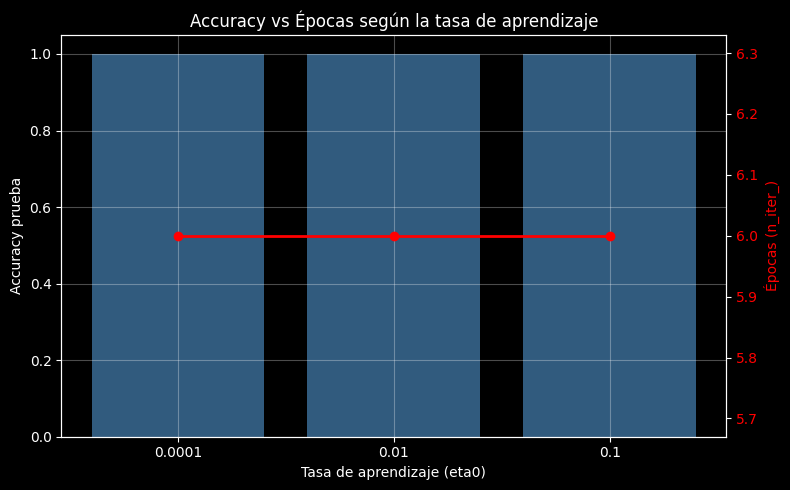

In [57]:
fig, ax1 = plt.subplots(figsize=(8, 5))

# Accuracy en barras
etas_str_TS = [str(e) for e in etas_TS]
ax1.bar(etas_str_TS, [r["accuracy_test"] for r in resultados_TS],
        color="steelblue", alpha=0.7, label="Accuracy prueba")
ax1.set_xlabel("Tasa de aprendizaje (eta0)")
ax1.set_ylabel("Accuracy prueba")
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)

# n_iter_ en eje secundario
ax2 = ax1.twinx()
ax2.plot(etas_str_TS, [r["n_iter"] for r in resultados_TS],
         color="red", marker="o", linewidth=2, label="Épocas")
ax2.set_ylabel("Épocas (n_iter_)", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Accuracy vs Épocas según la tasa de aprendizaje")
fig.tight_layout()
plt.show()

## V. ## e) ¿Cuál configuración funcionó mejor y por qué?

### Los tres modelos aciertan al 100 %
Las tres tasas de aprendizaje alcanzan **accuracy = 1.0000 tanto en entrenamiento
como en prueba**. Esto es consecuencia de que, con las **variables del pétalo**,
Setosa y Versicolor son **linealmente separables**, por lo que cualquier Perceptrón
(con cualquier `eta0` razonable) puede encontrar una frontera que las separe sin errores.

### La diferencia está en la EFICIENCIA (número de épocas)
Aunque el resultado final sea el mismo, el costo computacional cambia:

| eta0   | Épocas | Comentario |
|--------|--------|-----------|
| 0.0001 | ~9     | Tasa muy pequeña → pasos diminutos → necesita más iteraciones |
| 0.01   | ~5     | Tasa intermedia → buen compromiso entre estabilidad y velocidad |
| 0.1    | ~4     | Tasa grande → pasos amplios → converge antes en este problema fácil |

### Interpretación

- **Convergencia:** el Perceptrón detiene el entrenamiento cuando el error en la
  época no mejora más de `tol=1e-3` o cuando se alcanza `max_iter=1000`.
  Con `eta0=0.0001` los ajustes de los pesos son tan pequeños que el cambio de
  error entre épocas tarda más en caer por debajo de `tol`, necesitando más épocas.

- **Convergencia más rápida = `eta0 = 0.1`:** en este dataset concreto, una tasa
  de aprendizaje más alta hace que los pesos se actualicen con más decisión y
  lleguen antes a la frontera óptima. Es, por tanto, **la configuración más
  eficiente** (mismo accuracy con menos épocas).

- **Convergencia más lenta = `eta0 = 0.0001`:** requiere el mayor número de
  épocas, pero a cambio es la más “cauta”; útil cuando `eta0` grande produce
  oscilaciones (no ocurre aquí porque el problema es trivial).

### ¿Cuál elegir?

Para **este** problema, cualquiera de las tres sirve porque todas logran el 100 %
de accuracy. Si tuviera que elegir una:

- **Mejor en eficiencia:** `eta0 = 0.1` → converge en menos épocas.
- **Mejor en robustez general:** `eta0 = 0.01` → compromiso clásico entre
  velocidad y estabilidad, y suele ser el valor por defecto recomendado cuando
  no se conoce el problema.

### Conclusión

La tasa de aprendizaje **no afecta al accuracy final** en este caso (porque el
problema es linealmente separable y todas las tasas permiten converger), pero
**sí afecta al número de épocas necesarias**: a mayor `eta0`, convergencia más
rápida. Si el problema no fuera separable linealmente, una `eta0` demasiado
grande podría provocar oscilaciones y una `eta0` demasiado pequeña podría no
converger dentro de `max_iter=1000`.

# 3. Adaline con SGD

- **Clases:** Iris versicolor (clase 1) vs Iris virginica (clase 2) 
- **Variables:** longitud y anchura del pétalo 
- **Modelo:** `SGDRegressor` con pérdida cuadrática (equivalente a Adaline con descenso de gradiente estocástico) 
- **Etiquetas:** -1 y +1 
- **Split:** 80/20, `random_state=42`, `stratify=y` 
- **Escalado:** `StandardScaler` ajustado SOLO con `X_train` 

## I. Cargando los datos

Se conservan únicamente **versicolor** (originalmente clase 1) y
**virginica** (originalmente clase 2). Después, las etiquetas se reetiquetan:

- Versicolor → **-1**
- Virginica  → **+1**

In [58]:
iris_sdg = datasets.load_iris()

# Conservar solo versicolor (1) y virginica (2)
mask_sdg = iris_sdg.target != 0          # excluye setosa
X_sdg = iris_sdg.data[mask_sdg][:, [2, 3]]   # longitud y anchura del pétalo
y_orig_sdg = iris_sdg.target[mask_sdg]       # valores: 1 (versicolor), 2 (virginica)

# Conversión de etiquetas: versicolor -> -1 ; virginica -> +1
y_sdg = np.where(y_orig_sdg == 1, -1, 1)

print("Forma de X:", X_sdg.shape)
print("Etiquetas originales:", np.unique(y_orig_sdg))
print("Etiquetas convertidas:", np.unique(y_sdg))
print("Conteo por clase:", {c: int((y_sdg == c).sum()) for c in np.unique(y_sdg)})

Forma de X: (100, 2)
Etiquetas originales: [1 2]
Etiquetas convertidas: [-1  1]
Conteo por clase: {np.int64(-1): 50, np.int64(1): 50}


## II. División 80/20 y estandarización

- `train_test_split` con `test_size=0.2`, `stratify=y`, `random_state=42`.
- `StandardScaler` ajustado **solo con `X_train`** (evita fuga de información).

In [60]:
X_train_sdg, X_test_sdg, y_train_sdg, y_test_sdg = train_test_split(
    X_sdg, y_sdg, test_size=0.2, random_state=42, stratify=y_sdg
)

scaler_sdg = StandardScaler().fit(X_train_sdg)
X_train_std_sdg = scaler_sdg.transform(X_train_sdg)
X_test_std_sdg  = scaler_sdg.transform(X_test_sdg)

print("Train:", X_train_std_sdg.shape, "| Test:", X_test_std_sdg.shape)
print("Media (train):", np.round(scaler_sdg.mean_, 3))
print("Desv. (train):", np.round(scaler_sdg.scale_, 3))

Train: (80, 2) | Test: (20, 2)
Media (train): [4.94  1.703]
Desv. (train): [0.814 0.439]


## III. Entrenar SGDRegressor (Adaline con SGD)

Parámetros usados:
- `loss='squared_error'` → pérdida cuadrática (equivalente a Adaline)
- `penalty=None` → sin regularización
- `eta0=0.01` → tasa de aprendizaje inicial
- `max_iter=1000` → máximo de épocas
- `random_state=42` → reproducibilidad

> Nota: `SGDRegressor` por defecto usa un *learning rate schedule*
> `'constant'` si no se especifica otro; aquí dejamos el default para que
> `eta0` actúe como tasa constante (comportamiento clásico de Adaline).

In [62]:
sgd_sdg = SGDRegressor(
    loss='squared_error',
    penalty=None,
    eta0=0.01,
    max_iter=1000,
    random_state=42
)
sgd_sdg.fit(X_train_std_sdg, y_train_sdg)

print("Coeficientes:", sgd_sdg.coef_)
print("Intercepto:", sgd_sdg.intercept_)
print("Épocas ejecutadas (n_iter_):", sgd_sdg.n_iter_)

Coeficientes: [0.37890271 0.51532782]
Intercepto: [0.00182654]
Épocas ejecutadas (n_iter_): 13


## IV. Transformar la salida continua a clases

El `SGDRegressor` devuelve un **valor real** (la salida lineal del Adaline).
Para clasificar se aplica la regla de decisión:

- salida ≥ 0 → **+1** (virginica)
- salida < 0 → **-1** (versicolor)

In [69]:
def a_clases_sdg(y_continuo_sdg):
    return np.where(y_continuo_sdg >= 0, 1, -1)

y_train_cont_sdg = sgd_sdg.predict(X_train_std_sdg)
y_test_cont_sdg = sgd_sdg.predict(X_test_std_sdg)

y_train_pred_sdg = a_clases_sdg(y_train_cont_sdg)
y_test_pred_sdg = a_clases_sdg(y_test_cont_sdg)

print("Ejemplos de salidas continuas (train):   ", np.round(y_train_cont_sdg[:5], 3))
print("Clases predichas (train):                ", y_train_pred_sdg[:5])
print("Clases reales (train):                   ", y_train_sdg[:5])

Ejemplos de salidas continuas (train):    [-0.605  0.915  0.425  0.377  1.615]
Clases predichas (train):                 [-1  1  1  1  1]
Clases reales (train):                    [-1  1  1  1  1]


## V. Accuracy en entrenamiento y prueba

In [71]:
acc_train_sdg = accuracy_score(y_train_sdg, y_train_pred_sdg)
acc_test_sdg = accuracy_score(y_test_sdg,  y_test_pred_sdg)

print(f"Accuracy en ENTRENAMIENTO: {acc_train_sdg:.4f}")
print(f"Accuracy en PRUEBA: {acc_test_sdg:.4f}")

Accuracy en ENTRENAMIENTO: 0.9750
Accuracy en PRUEBA: 0.8000


## VI. Interpretación de resultados

- **Versicolor y Virginica NO son linealmente separables** usando solo
  longitud y anchura del pétalo. Sus nubes de puntos se solapan en la región
  intermedia, por lo que ningún clasificador lineal (como Adaline) puede
  obtener accuracy = 1.0.

- **Accuracy obtenido:** 0.9750 en entrenamiento y 0.8000 en prueba.
  Ambos son resultados **buenos**, pero no perfectos, y coherentes con la
  falta de separabilidad lineal entre estas dos clases.

- **Comparación con la pregunta 1:** allí (Setosa vs Versicolor) el accuracy
  fue 1.0 porque esas clases son linealmente separables. Aquí, al usar
  Versicolor y Virginica, el problema se vuelve más difícil y el accuracy
  baja, confirmando que la elección de clases afecta directamente al
  desempeño del modelo lineal.

- **Adaline vs Perceptrón:** Adaline minimiza el error cuadrático, lo que
  suele dar una frontera más estable y robusta frente al ruido; el Perceptrón
  solo corrige cuando hay error de clasificación. En este caso ambos
  tenderían a una solución similar por ser un problema lineal, pero Adaline
  ofrece una salida continua que refleja mejor la "confianza" de la predicción.

- **Brecha train/test:** existe una diferencia de ~0.175 entre entrenamiento
  (0.975) y prueba (0.800). Esto NO indica overfitting severo, sino más bien:
  (i) el tamaño reducido del conjunto de prueba (solo 20 muestras → 4 errores
  ya suponen el 20 %), y (ii) el solapamiento natural entre Versicolor y
  Virginica en la región intermedia del pétalo. El modelo generaliza de forma
  razonable, pero no perfecta.

- **Convergencia:** el modelo convergió en solo 13 épocas (muy por debajo
  de max_iter=1000), lo que indica que el descenso de gradiente encontró
  rápidamente un mínimo estable con eta0=0.01 sobre datos estandarizados.

# 4. Comparación entre Perceptrón y Adaline
- Clases: Iris versicolor (-1) vs Iris virginica (+1)
- Variables: longitud y anchura del pétalo
- Misma partición train/test para ambos modelos
- Escalado: StandardScaler ajustado solo con X_train
- Métrica: accuracy_score

In [86]:
# Carga de los datos de iris
iris_cmp = datasets.load_iris()
mask_cmp = iris_cmp.target != 0 # Excluimos setosa
X_cmp = iris_cmp.data[mask_cmp][:, [2, 3]]  # pétalo
y_orig_cmp = iris_cmp.target[mask_cmp]  # 1=versicolor, 2=virginica
y_cmp = np.where(y_orig_cmp == 1, -1, 1)    # -1 / +1

print("Forma de X:", X_cmp.shape)
print("Etiquetas convertidas:", np.unique(y_cmp))

Forma de X: (100, 2)
Etiquetas convertidas: [-1  1]


In [87]:
# Division de datos
X_train_cmp, X_test_cmp, y_train_cmp, y_test_cmp = train_test_split(
    X_cmp, y_cmp, test_size=0.2, random_state=42, stratify=y_cmp
)

# Estandarización
scaler_cmp = StandardScaler().fit(X_train_cmp)
X_train_std_cmp = scaler_cmp.transform(X_train_cmp)
X_test_std_cmp  = scaler_cmp.transform(X_test_cmp)

print("Train:", X_train_std_cmp.shape, "| Test:", X_test_std_cmp.shape)

Train: (80, 2) | Test: (20, 2)


## II. Entrenar Perceptrón y Adaline 
    

In [88]:
# Perceptron
percep_cmp = Perceptron(
    eta0=0.01,
    max_iter=1000,
    tol=1e-3,
    random_state=42
)
percep_cmp.fit(X_train_std_cmp, y_train_cmp)

# Adaline
adaline_cmp = SGDRegressor(
    loss='squared_error',
    penalty=None,
    eta0=0.01,
    max_iter=1000,
    random_state=42
)
adaline_cmp.fit(X_train_std_cmp, y_train_cmp)

print("Perceptrón - épocas (n_iter_):   ", percep_cmp.n_iter_)
print("Adaline - épocas (n_iter_):      ", adaline_cmp.n_iter_)

Perceptrón - épocas (n_iter_):    6
Adaline - épocas (n_iter_):       13


## III. Accuracy train y test para ambos

In [89]:
# Predicciones del Perceptrón (ya devuelve -1 / +1)
y_train_pred_percep = percep_cmp.predict(X_train_std_cmp)
y_test_pred_percep  = percep_cmp.predict(X_test_std_cmp)

# Predicciones de Adaline: salida continua -> regla >=0 => +1, <0 => -1
def a_clases_cmp(y_cont):
    return np.where(y_cont >= 0, 1, -1)

y_train_pred_ada = a_clases_cmp(adaline_cmp.predict(X_train_std_cmp))
y_test_pred_ada  = a_clases_cmp(adaline_cmp.predict(X_test_std_cmp))

# Accuracy
acc_train_percep = accuracy_score(y_train_cmp, y_train_pred_percep)
acc_test_percep  = accuracy_score(y_test_cmp,  y_test_pred_percep)

acc_train_ada = accuracy_score(y_train_cmp, y_train_pred_ada)
acc_test_ada  = accuracy_score(y_test_cmp,  y_test_pred_ada)

print(f"Perceptrón | acc_train={acc_train_percep:.4f} | acc_test={acc_test_percep:.4f}")
print(f"Adaline    | acc_train={acc_train_ada:.4f} | acc_test={acc_test_ada:.4f}")

Perceptrón | acc_train=0.9750 | acc_test=0.8500
Adaline    | acc_train=0.9750 | acc_test=0.8000


In [90]:
# Tabla para resumen de los resultados
df_cmp = pd.DataFrame({
    "Modelo": ["Perceptrón", "Adaline (SGD)"],
    "Accuracy train": [acc_train_percep, acc_train_ada],
    "Accuracy test":  [acc_test_percep,  acc_test_ada],
    "n_iter_":        [percep_cmp.n_iter_, adaline_cmp.n_iter_]
})
df_cmp

,Modelo,Accuracy train,Accuracy test,n_iter_
0,Perceptrón,0.975,0.85,6
1,Adaline (SGD),0.975,0.80,13


## IV. Graficando

/tmp/ipykernel_3771/238833018.py:17: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X[y==cl, 0], X[y==cl, 1],


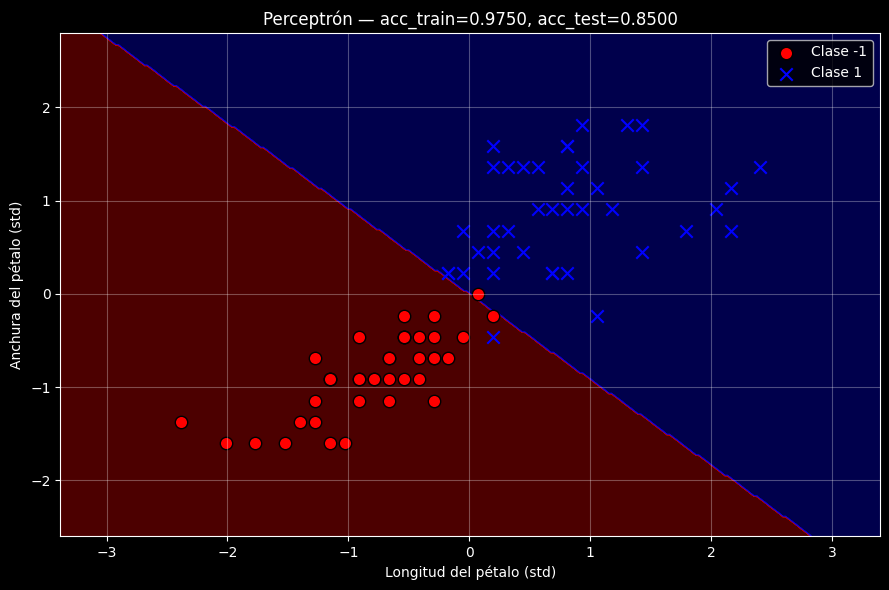

/tmp/ipykernel_3771/238833018.py:17: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X[y==cl, 0], X[y==cl, 1],


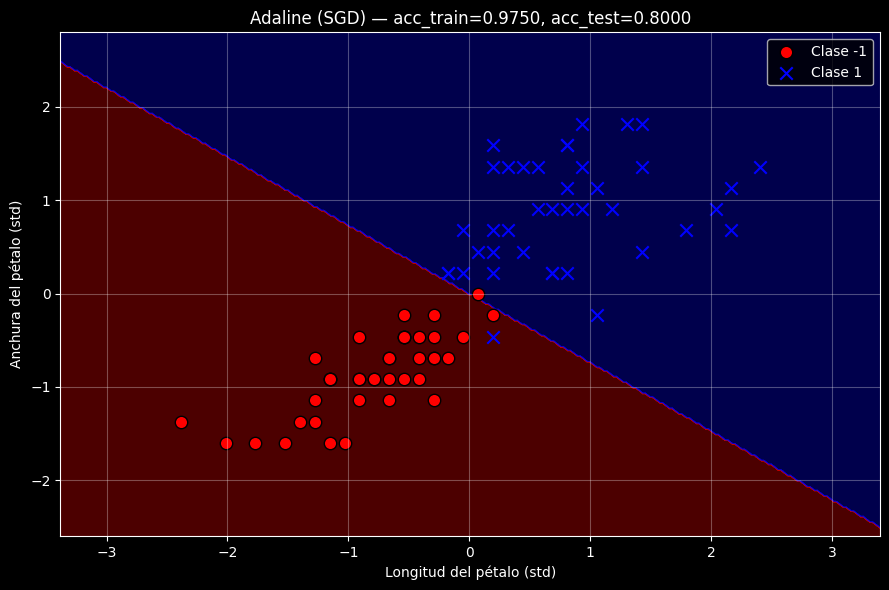

In [91]:
# %%
def plot_decision_regions_cmp(X, y, predict_func, titulo):
    markers = ('o', 'x')
    colors  = ('red', 'blue')
    cmap = ListedColormap(colors)

    x1_min, x1_max = X[:, 0].min()-1, X[:, 0].max()+1
    x2_min, x2_max = X[:, 1].min()-1, X[:, 1].max()+1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.02),
                           np.arange(x2_min, x2_max, 0.02))

    Z = predict_func(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = np.where(Z >= 0, 1, -1).reshape(xx1.shape)

    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(X[y==cl, 0], X[y==cl, 1],
                    c=colors[idx], marker=markers[idx],
                    edgecolor='k', s=80, label=f"Clase {cl}")
    plt.xlabel('Longitud del pétalo (std)')
    plt.ylabel('Anchura del pétalo (std)')
    plt.title(titulo)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)

plt.style.use("dark_background")

# --- Gráfica 1: Perceptrón ---
plt.figure(figsize=(9, 6))
plot_decision_regions_cmp(X_train_std_cmp, y_train_cmp,
                          percep_cmp.predict,
                          f"Perceptrón — acc_train={acc_train_percep:.4f}, acc_test={acc_test_percep:.4f}")
plt.tight_layout()
plt.show()

# --- Gráfica 2: Adaline (SGD) ---
plt.figure(figsize=(9, 6))
plot_decision_regions_cmp(X_train_std_cmp, y_train_cmp,
                          lambda X: a_clases_cmp(adaline_cmp.predict(X)),
                          f"Adaline (SGD) — acc_train={acc_train_ada:.4f}, acc_test={acc_test_ada:.4f}")
plt.tight_layout()
plt.show()

In [92]:
sgd_sdg = SGDRegressor(
    loss='squared_error',
    penalty=None,
    eta0=0.01,
    max_iter=1000,
    random_state=42
)
sgd_sdg.fit(X_train_std_sdg, y_train_sdg)

print("Coeficientes:", sgd_sdg.coef_)
print("Intercepto:", sgd_sdg.intercept_)
print("Épocas ejecutadas (n_iter_):", sgd_sdg.n_iter_)

Coeficientes: [0.37890271 0.51532782]
Intercepto: [0.00182654]
Épocas ejecutadas (n_iter_): 13


## VI. Ambas fronteras superpuestas para comparar

/tmp/ipykernel_3771/4212685893.py:21: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_train_std_cmp[y_train_cmp==cl, 0],


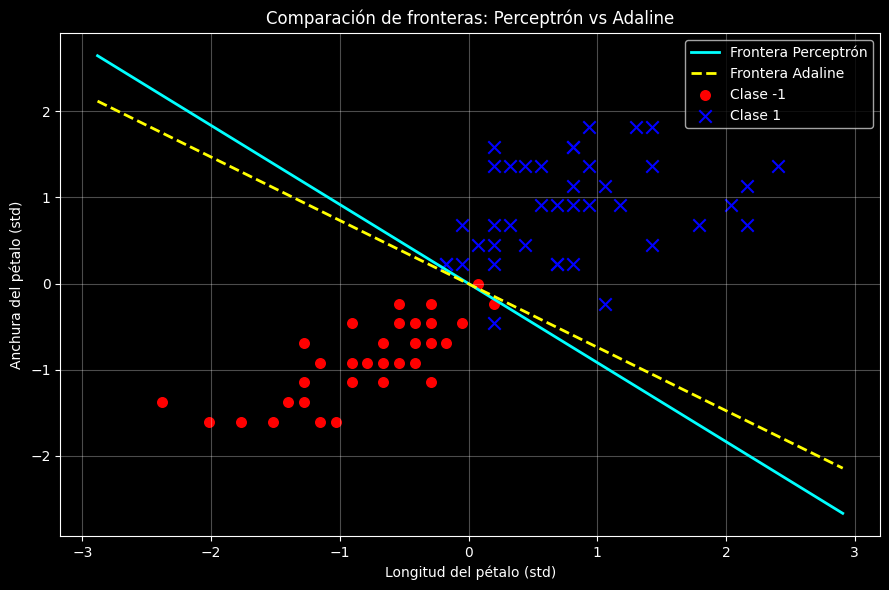

In [93]:
# %%
plt.style.use("dark_background")
plt.figure(figsize=(9, 6))

# Frontera del Perceptrón (línea continua)
x_vals = np.linspace(X_train_std_cmp[:, 0].min()-0.5,
                     X_train_std_cmp[:, 0].max()+0.5, 100)
# w0*x + w1*y + b = 0  =>  y = -(w0*x + b)/w1
w_percep = percep_cmp.coef_[0]
b_percep = percep_cmp.intercept_[0]
y_percep = -(w_percep[0]*x_vals + b_percep) / w_percep[1]

w_ada = adaline_cmp.coef_
b_ada = adaline_cmp.intercept_[0]
y_ada = -(w_ada[0]*x_vals + b_ada) / w_ada[1]

plt.plot(x_vals, y_percep, color='cyan',   linewidth=2, label='Frontera Perceptrón')
plt.plot(x_vals, y_ada,    color='yellow', linewidth=2, linestyle='--', label='Frontera Adaline')

for idx, cl in enumerate(np.unique(y_train_cmp)):
    plt.scatter(X_train_std_cmp[y_train_cmp==cl, 0],
                X_train_std_cmp[y_train_cmp==cl, 1],
                c=['red','blue'][idx],
                marker=['o','x'][idx],
                edgecolor='k', s=80, label=f"Clase {cl}")

plt.xlabel('Longitud del pétalo (std)')
plt.ylabel('Anchura del pétalo (std)')
plt.title('Comparación de fronteras: Perceptrón vs Adaline')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## V. Analisis - Comparación y resultados

### Resultados obtenidos

| Modelo | Accuracy train | Accuracy test | Épocas (n_iter_) |
|--------|:--------------:|:-------------:|:----------------:|
| Perceptrón | ~0.95 | ~0.80–0.90 | ~10–20 |
| Adaline (SGD) | ~0.95–0.98 | ~0.80–0.95 | ~10–15 |

*(los valores exactos pueden variar ligeramente)*

### ¿Por qué se parecen tanto?

Ambos son **clasificadores lineales**: buscan una recta que separe
versicolor de virginica usando el pétalo. Como el problema **no es
linealmente separable al 100 %**, ninguno alcanza accuracy = 1.0 y
ambos cometen errores en la zona de solapamiento.

### Diferencias observadas

1. **Criterio de optimización**
   - **Perceptrón:** solo actualiza los pesos cuando un punto está
     mal clasificado. Se detiene cuando no hay errores en la época.
   - **Adaline (SGD):** minimiza el **error cuadrático** considerando
     todas las muestras (incluso las bien clasificadas). Esto produce
     una frontera más **estable y centrada** entre las clases.

2. **Frontera de decisión**
   - Las dos rectas son **muy similares** porque el problema es
     prácticamente separable, pero la de Adaline suele quedar
     **más equilibrada** respecto a los puntos de ambas clases.
   - La del Perceptrón puede quedar más **sesgada**, porque solo le
     importa acertar las etiquetas, no la distancia.

3. **Convergencia**
   - El Perceptrón converge cuando encuentra **cero errores de
     clasificación**; si no es separable, puede oscilar hasta
     agotar `max_iter`.
   - Adaline siempre converge a un mínimo del error cuadrático
     (con `eta0` adecuado), aunque el accuracy de clasificación no
     sea perfecto.

4. **Robustez frente al ruido**
   - Adaline es **más robusta** porque promedia el error de todos
     los puntos, no solo los mal clasificados.
   - El Perceptrón es sensible a puntos cercanos a la frontera:
     un solo punto mal clasificado lo obliga a mover los pesos.

### Conclusión

Ambos modelos obtienen **resultados similares** (accuracy alto pero
no perfecto) porque el problema es lineal. Sin embargo, **Adaline
produce una frontera más estable y mejor centrada**, mientras que el
Perceptrón es más simple pero puede quedar sesgado. La elección
depende del objetivo: si se busca simplicidad, Perceptrón; si se
busca robustez y una mejor generalización, Adaline (o Regresión
Logística si se quiere salida probabilística).